In [ ]:
aimport tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

### 1. Download and Load the MNIST Dataset

The MNIST dataset is a classic dataset of handwritten digits. Keras provides a convenient way to load it.

In [ ]:
# Load the MNIST dataset
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()

print(f"Training images shape: {train_images.shape}")
print(f"Training labels shape: {train_labels.shape}")
print(f"Test images shape: {test_images.shape}")
print(f"Test labels shape: {test_labels.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


### 2. Preprocess the Data

For a CNN, the images typically need to be reshaped to include a channel dimension (e.g., (height, width, channels)). For grayscale images like MNIST, this will be 1 channel. We also need to normalize the pixel values to a range between 0 and 1.

In [ ]:
# Reshape images to add a channel dimension (for CNNs)
# MNIST images are 28x28 grayscale, so reshape to (28, 28, 1)

train_images = train_images.reshape((60000, 28, 28, 1))
test_images = test_images.reshape((10000, 28, 28, 1))

# Normalize pixel values to be between 0 and 1
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

print(f"Reshaped and normalized training images shape: {train_images.shape}")
print(f"Reshaped and normalized test images shape: {test_images.shape}")

Reshaped and normalized training images shape: (60000, 28, 28, 1)
Reshaped and normalized test images shape: (10000, 28, 28, 1)


### 3. Create a Convolutional Neural Network (CNN) Model

Now, let's define a simple CNN model. This model will take the preprocessed image matrices as input.

In [ ]:
# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax') # 10 classes for digits 0-9
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Display the model summary
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

The CNN model is now defined and ready for training! It takes input images of shape `(28, 28, 1)`.

### 4. Train the CNN Model

Now, let's train the model using the `train_images` and `train_labels` and validate it using `test_images` and `test_labels`.

In [ ]:
history = model.fit(train_images, train_labels, epochs=5,
                    validation_data=(test_images, test_labels))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 54s 28ms/step - accuracy: 0.9546 - loss: 0.1474 - val_accuracy: 0.9885 - val_loss: 0.0363
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 28ms/step - accuracy: 0.9850 - loss: 0.0479 - val_accuracy: 0.9895 - val_loss: 0.0312
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9897 - loss: 0.0329 - val_accuracy: 0.9879 - val_loss: 0.0415
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 28ms/step - accuracy: 0.9914 - loss: 0.0268 - val_accuracy: 0.9923 - val_loss: 0.0254
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 51s 27ms/step - accuracy: 0.9937 - loss: 0.0194 - val_accuracy: 0.9911 - val_loss: 0.0284


### 5. Evaluate the Model

Let's evaluate the trained model on the test dataset to see its accuracy.

In [ ]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"\nTest accuracy: {test_acc}")

313/313 - 2s - 8ms/step - accuracy: 0.9911 - loss: 0.0284

Test accuracy: 0.991100013256073


### 6. Test with Sample Images

Let's pick a few images from the test set and see how our trained model predicts them.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


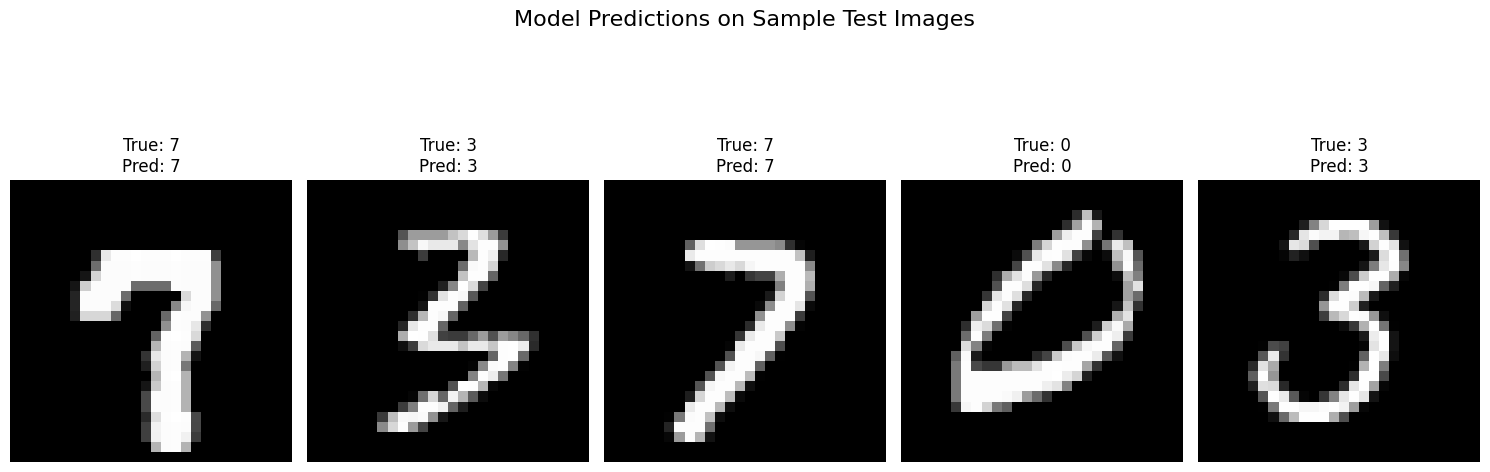

In [ ]:
# Select a few random images from the test set
num_samples = 5
random_indices = np.random.choice(len(test_images), num_samples, replace=False)

sample_images = test_images[random_indices]
sample_labels = test_labels[random_indices]

# Make predictions
predictions = model.predict(sample_images)

# Plot the images and their predictions
plt.figure(figsize=(15, 6))
for i in range(num_samples):
    plt.subplot(1, num_samples, i + 1)
    plt.imshow(sample_images[i].reshape(28, 28), cmap='gray')
    plt.title(f"True: {sample_labels[i]}\nPred: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.suptitle('Model Predictions on Sample Test Images', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make space for suptitle
plt.show()